# Sugar Cosmetics Instagram Analytics
## Data validation, cleaning, quality checks and exploratory data analysis

**Purpose:** prepare and assess the supplied Instagram analytics dataset before using it in the Streamlit dashboard.

This notebook:
1. Loads the original workbook when available, with a project CSV fallback.
2. standardizes column names and data types.
3. checks missingness, duplicates, invalid values and logical inconsistencies.
4. investigates distributions, outliers and category balance.
5. engineers documented engagement and conversion-proxy metrics.
6. exports the cleaned dataset and a machine-readable quality report.

> **Data provenance limitation:** the supplied workbook does not establish whether these records are official Sugar Cosmetics account data, simulated data, or a sampled dataset. Findings below describe the supplied file only. Do not present them as verified real-world brand performance without independent provenance evidence.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import json
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_PATH = DATA_DIR / "sugar_cosmetics_instagram_data.xlsx"
CSV_PATH = DATA_DIR / "sugar_cosmetics_instagram_data.csv"

print("Project root:", PROJECT_ROOT.resolve())
print("Excel available:", EXCEL_PATH.exists())
print("CSV available:", CSV_PATH.exists())

Project root: D:\sugar_cosmetics_instagram_analytics
Excel available: True
CSV available: True


## 2. Load the source data

In [2]:
if EXCEL_PATH.exists():
    raw = pd.read_excel(EXCEL_PATH)
    source_used = str(EXCEL_PATH)
elif CSV_PATH.exists():
    raw = pd.read_csv(CSV_PATH)
    source_used = str(CSV_PATH)
else:
    raise FileNotFoundError(
        "Place sugar_cosmetics_instagram_data.xlsx or the project CSV in the data/ folder."
    )

source_shape = raw.shape
original_columns = raw.columns.tolist()

def standardize_column(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

raw.columns = [standardize_column(c) for c in raw.columns]

print(f"Source: {source_used}")
print(f"Rows: {source_shape[0]:,} | Columns: {source_shape[1]}")
print("Standardized columns:", raw.columns.tolist())
display(raw.head())

Source: d:\sugar_cosmetics_instagram_analytics\data\sugar_cosmetics_instagram_data.xlsx
Rows: 50,000 | Columns: 14
Standardized columns: ['post_date', 'post_type', 'campaign_type', 'hashtags', 'audience_emotion', 'engagement_source', 'impressions', 'reach', 'likes', 'comments', 'shares', 'saves', 'profile_visits', 'follows']


,post_date,post_type,campaign_type,hashtags,audience_emotion,engagement_source,impressions,reach,likes,comments,shares,saves,profile_visits,follows
0,2024-12-23,Story,Giveaway,"#SugarCosmetics, #MakeupGoals, #BoldLooks",Curious,Collab,16795,15665,3076,430,73,99,193,86
1,2024-06-01,Image,Tutorial,"#BoldLooks, #MakeupGoals, #VeganBeauty",Confident,Influencer,45131,29335,5285,308,396,502,294,146
2,2024-04-28,Reel,Festive Offer,#VeganBeauty,Confident,Collab,18568,13118,2032,233,73,140,204,44
3,2025-02-01,Reel,Product Launch,"#CrueltyFree, #VeganBeauty, #SugarCosmetics",Happy,Collab,1189,751,130,13,12,7,33,12
4,2024-08-04,Story,Tutorial,"#SugarCosmetics, #VeganBeauty",Curious,Organic,15502,9373,2234,300,99,47,180,35


## 3. Schema and type validation

In [3]:
required_columns = {
    "post_date", "post_type", "campaign_type", "hashtags", "audience_emotion",
    "engagement_source", "impressions", "reach", "likes", "comments",
    "shares", "saves", "profile_visits", "follows"
}
missing_required = sorted(required_columns - set(raw.columns))
unexpected_columns = sorted(set(raw.columns) - required_columns)

if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

df = raw.copy()
df["post_date"] = pd.to_datetime(df["post_date"], errors="coerce")

numeric_columns = [
    "impressions", "reach", "likes", "comments", "shares", "saves",
    "profile_visits", "follows"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

categorical_columns = [
    "post_type", "campaign_type", "hashtags", "audience_emotion", "engagement_source"
]
for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

schema = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_pct": [float(df[c].isna().mean() * 100) for c in df.columns],
    "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns]
})
display(schema)
print("Unexpected columns:", unexpected_columns or "None")

,column,dtype,missing_count,missing_pct,unique_values
0,post_date,datetime64[ns],0,0.0000,366
1,post_type,string,0,0.0000,4
2,campaign_type,string,0,0.0000,5
3,hashtags,string,0,0.0000,85
4,audience_emotion,string,0,0.0000,5
5,engagement_source,string,0,0.0000,4
6,impressions,int64,0,0.0000,31462
7,reach,int64,0,0.0000,29010
8,likes,int64,0,0.0000,8604
9,comments,int64,0,0.0000,1677


Unexpected columns: None


## 4. Data quality checks

In [4]:
quality_checks = []

def add_check(name, count, severity="Review", detail=""):
    quality_checks.append({
        "check": name,
        "count": int(count),
        "severity": severity,
        "detail": detail
    })

add_check("Missing cells", df.isna().sum().sum(), "Review",
          "Missingness is assessed at cell level; investigate any non-zero result.")
add_check("Exact duplicate rows", df.duplicated().sum(), "Review",
          "Without a post ID, exact duplicates are not the same as confirmed duplicate posts.")
add_check("Invalid/missing post dates", df["post_date"].isna().sum(), "High",
          "Rows with invalid dates cannot be used in time-based analyses.")
for col in numeric_columns:
    add_check(f"Missing/non-numeric values in {col}", df[col].isna().sum(), "Review",
              "Check original source values before imputation or removal.")
    add_check(f"Negative values in {col}", (df[col] < 0).sum(), "High",
              "Negative count metrics are usually invalid and require source review.")

add_check("Impressions lower than reach", (df["impressions"] < df["reach"]).sum(), "Review",
          "Reach and impressions definitions can vary; verify these records rather than silently changing them.")
engagements_raw = df[["likes", "comments", "shares", "saves"]].sum(axis=1, min_count=4)
add_check("Engagement actions exceed reach", (engagements_raw > df["reach"]).sum(), "Review",
          "Repeated actions or metric definitions may explain some cases; inspect rather than assume impossible.")
add_check("Zero reach", (df["reach"] == 0).sum(), "Review",
          "Engagement rate is undefined when reach is zero.")
add_check("Zero profile visits", (df["profile_visits"] == 0).sum(), "Info",
          "Follow-per-visit proxy is undefined when profile visits are zero.")

quality_df = pd.DataFrame(quality_checks)
display(quality_df)

,check,count,severity,detail
0,Missing cells,0,Review,Missingness is assessed at cell level; investi...
1,Exact duplicate rows,0,Review,"Without a post ID, exact duplicates are not th..."
2,Invalid/missing post dates,0,High,Rows with invalid dates cannot be used in time...
3,Missing/non-numeric values in impressions,0,Review,Check original source values before imputation...
4,Negative values in impressions,0,High,Negative count metrics are usually invalid and...
5,Missing/non-numeric values in reach,0,Review,Check original source values before imputation...
6,Negative values in reach,0,High,Negative count metrics are usually invalid and...
7,Missing/non-numeric values in likes,0,Review,Check original source values before imputation...
8,Negative values in likes,0,High,Negative count metrics are usually invalid and...
9,Missing/non-numeric values in comments,0,Review,Check original source values before imputation...


## 5. Cleaning decisions

In [5]:
# Preserve an untouched copy in memory for auditability.
clean = df.copy()

# We do not drop rows automatically. The current workbook's provenance and row grain
# are not documented, so any exclusion should be justified and recorded.
# Normalize whitespace in string fields; preserve missing values.
for col in categorical_columns:
    clean[col] = clean[col].astype("string").str.strip()

# Derived metrics use explicit denominators. Zero denominators produce NaN, not infinity.
clean["total_engagements"] = clean[["likes", "comments", "shares", "saves"]].sum(axis=1, min_count=4)
clean["engagement_rate"] = np.where(
    clean["reach"] > 0, clean["total_engagements"] / clean["reach"], np.nan
)
clean["profile_visit_rate_proxy"] = np.where(
    clean["reach"] > 0, clean["profile_visits"] / clean["reach"], np.nan
)
clean["follow_per_visit_rate_proxy"] = np.where(
    clean["profile_visits"] > 0, clean["follows"] / clean["profile_visits"], np.nan
)
clean["follow_per_reach_rate_proxy"] = np.where(
    clean["reach"] > 0, clean["follows"] / clean["reach"], np.nan
)
clean["month"] = clean["post_date"].dt.to_period("M").astype("string")
clean["weekday"] = clean["post_date"].dt.day_name().astype("string")

print("Rows before cleaning:", len(df))
print("Rows after non-destructive standardization:", len(clean))
print("Rows automatically dropped: 0")
print("Rationale: preserve traceability until provenance, row grain and exclusion rules are confirmed.")
display(clean.head())

Rows before cleaning: 50000
Rows after non-destructive standardization: 50000
Rows automatically dropped: 0
Rationale: preserve traceability until provenance, row grain and exclusion rules are confirmed.


,post_date,post_type,campaign_type,hashtags,audience_emotion,engagement_source,impressions,reach,likes,comments,shares,saves,profile_visits,follows,total_engagements,engagement_rate,profile_visit_rate_proxy,follow_per_visit_rate_proxy,follow_per_reach_rate_proxy,month,weekday
0,2024-12-23,Story,Giveaway,"#SugarCosmetics, #MakeupGoals, #BoldLooks",Curious,Collab,16795,15665,3076,430,73,99,193,86,3678,0.2348,0.0123,0.4456,0.0055,2024-12,Monday
1,2024-06-01,Image,Tutorial,"#BoldLooks, #MakeupGoals, #VeganBeauty",Confident,Influencer,45131,29335,5285,308,396,502,294,146,6491,0.2213,0.0100,0.4966,0.0050,2024-06,Saturday
2,2024-04-28,Reel,Festive Offer,#VeganBeauty,Confident,Collab,18568,13118,2032,233,73,140,204,44,2478,0.1889,0.0156,0.2157,0.0034,2024-04,Sunday
3,2025-02-01,Reel,Product Launch,"#CrueltyFree, #VeganBeauty, #SugarCosmetics",Happy,Collab,1189,751,130,13,12,7,33,12,162,0.2157,0.0439,0.3636,0.0160,2025-02,Saturday
4,2024-08-04,Story,Tutorial,"#SugarCosmetics, #VeganBeauty",Curious,Organic,15502,9373,2234,300,99,47,180,35,2680,0.2859,0.0192,0.1944,0.0037,2024-08,Sunday


## 6. Numeric distributions and outlier screening

In [6]:
display(clean[numeric_columns + ["total_engagements", "engagement_rate"]].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)

# IQR screening flags possible extreme values; it does not delete or winsorize them.
outlier_rows = []
for col in numeric_columns + ["total_engagements", "engagement_rate"]:
    s = clean[col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (clean[col] < lower) | (clean[col] > upper)
    outlier_rows.append({
        "metric": col, "q1": q1, "q3": q3, "iqr": iqr,
        "lower_iqr_fence": lower, "upper_iqr_fence": upper,
        "flagged_count": int(mask.sum()), "flagged_pct": float(mask.mean() * 100)
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
print("Interpretation: IQR flags are review candidates, not proof of erroneous data.")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
impressions,"50,000.0000","25,520.9150","14,118.6535","1,002.0000","1,527.9900","3,478.9500","13,243.0000","25,541.0000","37,758.2500","47,529.1500","49,507.0000","49,999.0000"
reach,"50,000.0000","19,748.4658","11,311.9625",616.0000,"1,162.9900","2,651.9000","10,157.7500","19,393.5000","28,763.2500","38,659.0000","43,523.0100","47,329.0000"
likes,"50,000.0000","2,954.5656","2,144.9189",40.0000,138.0000,330.0000,"1,256.0000","2,466.0000","4,255.0000","7,184.0000","9,024.0000","11,392.0000"
comments,"50,000.0000",369.1872,311.6765,2.0000,14.0000,35.0000,135.0000,282.0000,516.0000,"1,005.0000","1,384.0000","2,205.0000"
shares,"50,000.0000",162.3068,151.7225,0.0000,4.0000,13.0000,50.0000,114.0000,228.0000,477.0000,677.0000,"1,072.0000"
saves,"50,000.0000",177.2288,154.9493,1.0000,6.0000,16.0000,62.0000,132.0000,246.0000,496.0000,702.0000,"1,057.0000"
profile_visits,"50,000.0000",592.6960,428.2218,7.0000,28.0000,65.0000,252.0000,497.0000,851.0000,"1,435.0000","1,796.0100","2,264.0000"
follows,"50,000.0000",177.3342,154.5508,0.0000,6.0000,16.0000,63.0000,133.0000,245.0000,496.0000,695.0000,"1,114.0000"
total_engagements,"50,000.0000","3,663.2883","2,669.3535",50.0000,170.0000,408.9500,"1,552.0000","3,058.5000","5,271.0000","8,912.0500","11,236.0100","14,980.0000"
engagement_rate,"50,000.0000",0.1854,0.0720,0.0559,0.0636,0.0739,0.1232,0.1849,0.2464,0.2981,0.3170,0.3410


,metric,q1,q3,iqr,lower_iqr_fence,upper_iqr_fence,flagged_count,flagged_pct
0,impressions,"13,243.0000","37,758.2500","24,515.2500","-23,529.8750","74,531.1250",0,0.0000
1,reach,"10,157.7500","28,763.2500","18,605.5000","-17,750.5000","56,671.5000",0,0.0000
2,likes,"1,256.0000","4,255.0000","2,999.0000","-3,242.5000","8,753.5000",674,1.3480
3,comments,135.0000,516.0000,381.0000,-436.5000,"1,087.5000",1836,3.6720
4,shares,50.0000,228.0000,178.0000,-217.0000,495.0000,2180,4.3600
5,saves,62.0000,246.0000,184.0000,-214.0000,522.0000,2101,4.2020
6,profile_visits,252.0000,851.0000,599.0000,-646.5000,"1,749.5000",635,1.2700
7,follows,63.0000,245.0000,182.0000,-210.0000,518.0000,2152,4.3040
8,total_engagements,"1,552.0000","5,271.0000","3,719.0000","-4,026.5000","10,849.5000",689,1.3780
9,engagement_rate,0.1232,0.2464,0.1232,-0.0616,0.4312,0,0.0000


Interpretation: IQR flags are review candidates, not proof of erroneous data.


## 7. Visual exploratory data analysis

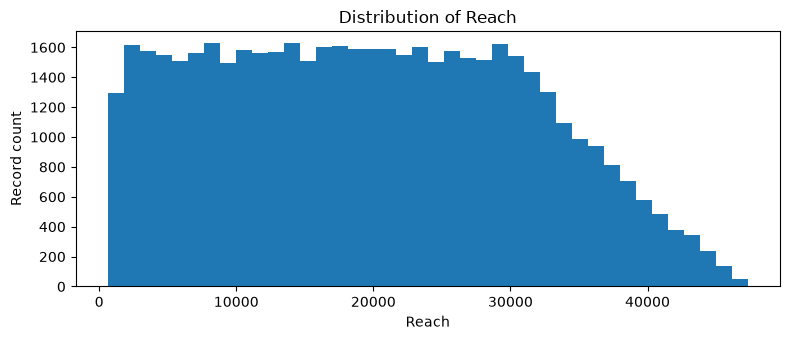

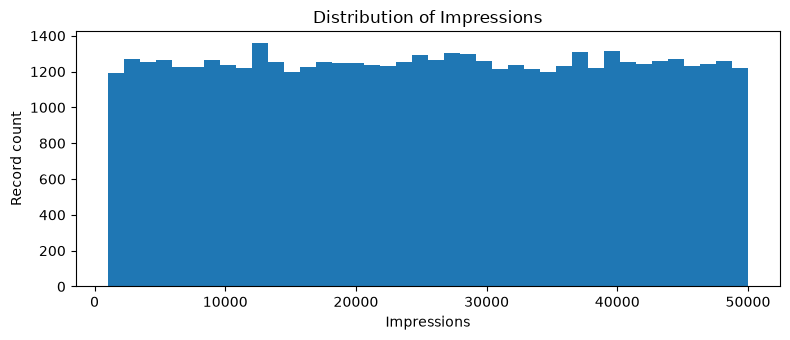

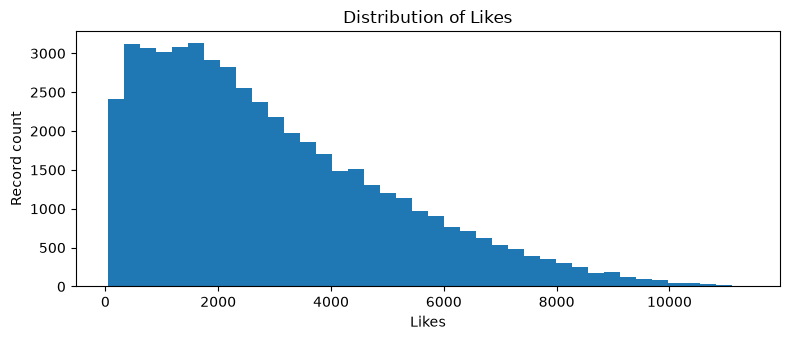

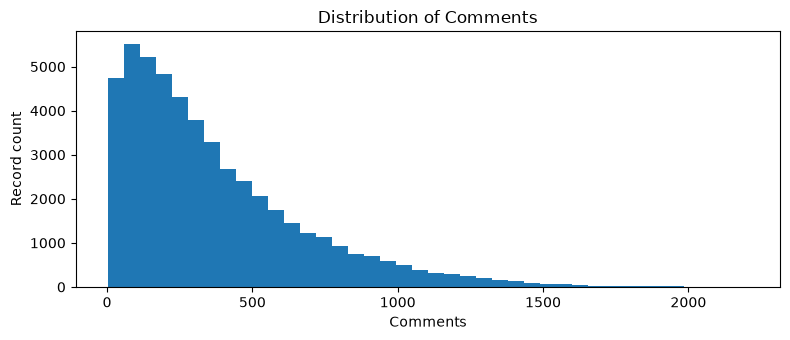

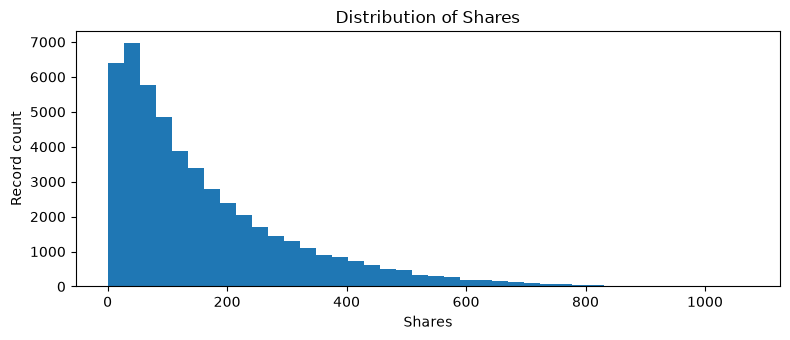

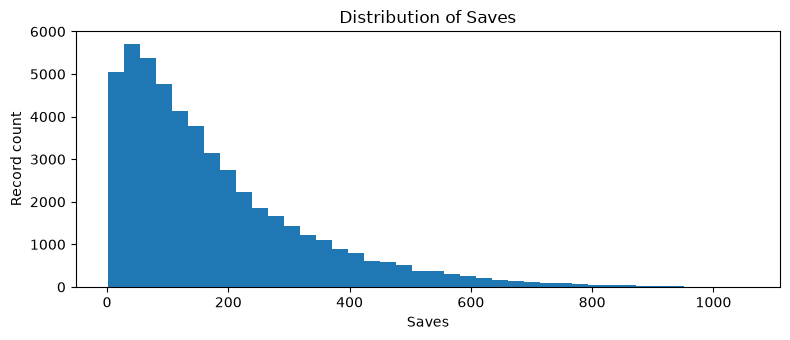

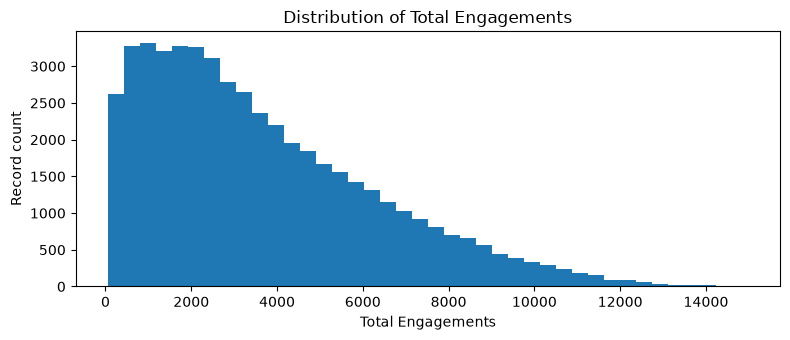

In [7]:
# Histograms help reveal skew and concentration; axes are metric-specific.
for col in ["reach", "impressions", "likes", "comments", "shares", "saves", "total_engagements"]:
    values = clean[col].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.hist(values, bins=40)
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Record count")
    fig.tight_layout()
    plt.show()

## 8. Category balance and group comparisons

In [8]:
def grouped_metrics(data, group_col):
    result = data.groupby(group_col, dropna=False).agg(
        records=(group_col, "size"),
        reach=("reach", "sum"),
        engagements=("total_engagements", "sum"),
        mean_post_engagement_rate=("engagement_rate", "mean"),
        likes=("likes", "sum"),
        comments=("comments", "sum"),
        shares=("shares", "sum"),
        saves=("saves", "sum"),
        profile_visits=("profile_visits", "sum"),
        follows=("follows", "sum")
    ).reset_index()
    result["weighted_engagement_rate"] = result["engagements"] / result["reach"].replace(0, np.nan)
    result["record_share_pct"] = result["records"] / max(len(data), 1) * 100
    return result.sort_values("weighted_engagement_rate", ascending=False)

post_type_summary = grouped_metrics(clean, "post_type")
campaign_summary = grouped_metrics(clean, "campaign_type")
source_summary = grouped_metrics(clean, "engagement_source")
emotion_summary = grouped_metrics(clean, "audience_emotion")

display(Markdown("### Post type"))
display(post_type_summary)
display(Markdown("### Campaign type"))
display(campaign_summary)
display(Markdown("### Engagement source"))
display(source_summary)
display(Markdown("### Audience emotion"))
display(emotion_summary)

for col in ["post_type", "campaign_type"]:
    print(f"\n{col} record counts:")
    display(clean[col].value_counts(dropna=False).rename_axis(col).reset_index(name="records"))

### Post type

,post_type,records,reach,engagements,mean_post_engagement_rate,likes,comments,shares,saves,profile_visits,follows,weighted_engagement_rate,record_share_pct
2,Story,12517,247114187,46026060,0.1860,37103330,4639443,2060546,2222741,7402697,2188756,0.1863,25.0340
1,Reel,12599,248574276,46225786,0.1861,37287896,4651643,2043615,2242632,7482881,2250700,0.1860,25.1980
3,Video,12485,245445633,45557380,0.1851,36716102,4620041,2018371,2202866,7337505,2203558,0.1856,24.9700
0,Image,12399,246289192,45355191,0.1843,36620951,4548234,1992806,2193200,7411715,2223696,0.1842,24.7980


### Campaign type

,campaign_type,records,reach,engagements,mean_post_engagement_rate,likes,comments,shares,saves,profile_visits,follows,weighted_engagement_rate,record_share_pct
2,Influencer Collab,9903,196818990,36671760,0.1860,29545521,3712221,1635714,1778304,5892815,1753487,0.1863,19.8060
4,Tutorial,10186,201732392,37500129,0.1858,30240552,3783937,1657682,1817958,6036912,1821742,0.1859,20.3720
1,Giveaway,9998,198096693,36759682,0.1857,29676382,3699138,1628288,1755874,5970107,1783676,0.1856,19.9960
3,Product Launch,9923,195905924,36282071,0.1849,29264841,3651250,1602476,1763504,5866560,1756982,0.1852,19.8460
0,Festive Offer,9990,194869289,35950775,0.1844,29000983,3612815,1591178,1745799,5868404,1750823,0.1845,19.9800


### Engagement source

,engagement_source,records,reach,engagements,mean_post_engagement_rate,likes,comments,shares,saves,profile_visits,follows,weighted_engagement_rate,record_share_pct
1,Influencer,12501,246260595,45938061,0.1858,37071379,4615613,2036141,2214928,7362380,2192584,0.1865,25.0020
0,Collab,12633,248952629,46382206,0.1859,37388521,4688074,2065133,2240478,7488501,2239054,0.1863,25.2660
3,Paid,12358,242421718,44960053,0.1853,36247163,4552867,1980854,2179169,7278623,2195482,0.1855,24.7160
2,Organic,12508,249788346,45884097,0.1844,37021216,4602807,2033210,2226864,7505294,2239590,0.1837,25.0160


... (2 outputs left out)


post_type record counts:


,post_type,records
0,Reel,12599
1,Story,12517
2,Video,12485
3,Image,12399



campaign_type record counts:


,campaign_type,records
0,Tutorial,10186
1,Giveaway,9998
2,Festive Offer,9990
3,Product Launch,9923
4,Influencer Collab,9903


## 9. Time trends

,post_date,records,reach,impressions,engagements,follows,weighted_engagement_rate
0,2024-04-01,1626,32420356,41922382,5911391,286955,0.1823
1,2024-05-01,4250,83453920,107568017,15476837,750337,0.1855
2,2024-06-01,4232,84035874,108511343,15639976,752157,0.1861
3,2024-07-01,4121,80383561,104154687,14873164,722283,0.1850
4,2024-08-01,4242,84298737,108812195,15530135,762358,0.1842
5,2024-09-01,4160,81579614,105615568,15237467,721750,0.1868
6,2024-10-01,4225,83992149,108763442,15489560,760070,0.1844
7,2024-11-01,4075,80335997,103473406,14920330,718169,0.1857
8,2024-12-01,4296,84135676,108890083,15590616,759950,0.1853
9,2025-01-01,4244,83461303,108007564,15647029,758759,0.1875


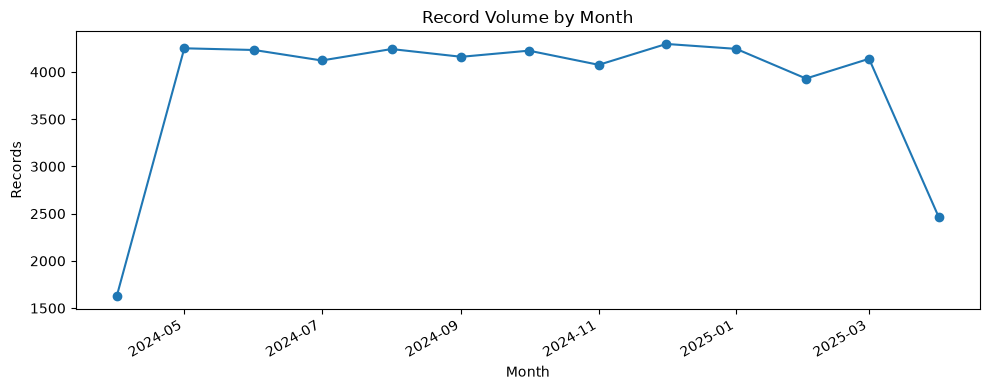

,weekday,records,reach,engagements,mean_post_engagement_rate,likes,comments,shares,saves,profile_visits,follows,weighted_engagement_rate,record_share_pct
1,Monday,7094,140535656,26031326,0.1848,20986739,2635374,1143248,1265965,4217836,1266877,0.1852,14.1880
5,Tuesday,7355,145331388,26972261,0.1857,21757600,2714471,1195281,1304909,4374078,1293815,0.1856,14.7100
6,Wednesday,7179,142650866,26469870,0.1863,21349519,2671249,1179894,1269208,4269650,1288983,0.1856,14.3580
4,Thursday,7068,140030360,25956946,0.1848,20957119,2609053,1137038,1253736,4179954,1250471,0.1854,14.1360
0,Friday,7245,143101982,26629803,0.1857,21463721,2680122,1192446,1293514,4330826,1287800,0.1861,14.4900
2,Saturday,7031,137103998,25492755,0.1860,20574250,2558051,1127547,1232907,4080846,1233109,0.1859,14.0620
3,Sunday,7028,138669038,25611456,0.1842,20639331,2591041,1139884,1241200,4181608,1245655,0.1847,14.0560


In [10]:
valid_dates = clean.dropna(subset=["post_date"]).copy()
valid_dates["post_date"] = pd.to_datetime(
    valid_dates["post_date"], errors="coerce"
)
valid_dates = valid_dates.dropna(subset=["post_date"])

# Aggregate monthly metrics
monthly = (
    valid_dates
    .set_index("post_date")
    .resample("MS")
    .agg(
        records=("reach", "size"),
        reach=("reach", "sum"),
        impressions=("impressions", "sum"),
        engagements=("total_engagements", "sum"),
        follows=("follows", "sum")
    )
    .reset_index()
)

monthly["weighted_engagement_rate"] = (
    monthly["engagements"]
    / monthly["reach"].replace(0, np.nan)
)

display(monthly)

# Plot monthly record volume
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly["post_date"], monthly["records"], marker="o")
ax.set_title("Record Volume by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Records")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# Engagement metrics by weekday
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday = grouped_metrics(valid_dates, "weekday")
weekday["weekday"] = pd.Categorical(
    weekday["weekday"],
    categories=weekday_order,
    ordered=True
)
weekday = weekday.sort_values("weekday")

display(weekday)


## 10. Hashtag analysis

In [11]:
hashtag_rows = []
for _, row in clean[["hashtags", "reach", "total_engagements", "likes", "comments", "shares", "saves", "follows"]].iterrows():
    tags = set(tag.lower() for tag in re.findall(r"#\w+", str(row["hashtags"])))
    for tag in tags:
        hashtag_rows.append({
            "hashtag": tag, "reach": row["reach"], "engagements": row["total_engagements"],
            "likes": row["likes"], "comments": row["comments"], "shares": row["shares"],
            "saves": row["saves"], "follows": row["follows"]
        })

if hashtag_rows:
    hashtag_df = pd.DataFrame(hashtag_rows)
    hashtag_summary = hashtag_df.groupby("hashtag").agg(
        records=("hashtag", "size"), reach=("reach", "sum"), engagements=("engagements", "sum"),
        likes=("likes", "sum"), comments=("comments", "sum"), shares=("shares", "sum"),
        saves=("saves", "sum"), follows=("follows", "sum")
    ).reset_index()
    hashtag_summary["weighted_engagement_rate"] = hashtag_summary["engagements"] / hashtag_summary["reach"].replace(0, np.nan)
    hashtag_summary = hashtag_summary.sort_values("weighted_engagement_rate", ascending=False)
    display(hashtag_summary.head(30))
else:
    hashtag_summary = pd.DataFrame()
    print("No parseable hashtags found.")
print("Hashtag groups overlap: a record with multiple hashtags contributes to each relevant hashtag.")

,hashtag,records,reach,engagements,likes,comments,shares,saves,follows,weighted_engagement_rate
4,#veganbeauty,19982,395276422,73748880,59449420,7438199,3275155,3586106,3545126,0.1866
0,#boldlooks,19956,396241790,73651357,59390980,7432937,3255611,3571829,3544381,0.1859
2,#makeupgoals,20018,396557791,73561353,59327018,7415054,3273151,3546130,3552420,0.1855
1,#crueltyfree,20197,401023498,74367686,60000026,7483497,3290321,3593842,3607636,0.1854
3,#sugarcosmetics,19891,392559171,72678345,58603884,7348035,3210123,3516303,3517438,0.1851


Hashtag groups overlap: a record with multiple hashtags contributes to each relevant hashtag.


## 11. Findings, assumptions and limitations

In [12]:
summary = {
    "source_file": source_used,
    "rows": int(len(clean)),
    "columns_after_feature_engineering": int(len(clean.columns)),
    "date_min": str(clean["post_date"].min()),
    "date_max": str(clean["post_date"].max()),
    "missing_cells_after_standardization": int(clean.isna().sum().sum()),
    "exact_duplicate_rows": int(clean.duplicated().sum()),
    "invalid_dates": int(clean["post_date"].isna().sum()),
    "post_type_categories": {str(k): int(v) for k, v in clean["post_type"].value_counts(dropna=False).items()},
    "campaign_type_categories": {str(k): int(v) for k, v in clean["campaign_type"].value_counts(dropna=False).items()},
    "provenance": "Not established by supplied workbook",
    "cleaning_policy": "Non-destructive standardization; no rows automatically dropped",
    "notes": [
        "No caption or post ID field is present in the supplied schema.",
        "No publication time, follower count, demographic attributes, spend or revenue fields are present.",
        "Summed post-level reach is not unique account reach.",
        "Engagement differences are descriptive and do not establish causality.",
        "IQR outliers are flagged for review, not automatically removed."
    ]
}
display(Markdown("### Dataset summary"))
display(pd.DataFrame([{"metric": k, "value": json.dumps(v) if isinstance(v, (dict, list)) else v} for k, v in summary.items()]))

print("Interpretation checklist:")
print("1. Confirm data provenance and whether one row represents one post.")
print("2. Review every non-zero validation flag against source definitions.")
print("3. Inspect flagged outliers; do not delete them solely because they are extreme.")
print("4. Avoid demographic, posting-hour, ROI or causal claims without supporting fields/design.")

### Dataset summary

,metric,value
0,source_file,d:\sugar_cosmetics_instagram_analytics\data\su...
1,rows,50000
2,columns_after_feature_engineering,21
3,date_min,2024-04-19 00:00:00
4,date_max,2025-04-19 00:00:00
5,missing_cells_after_standardization,0
6,exact_duplicate_rows,0
7,invalid_dates,0
8,post_type_categories,"{""Reel"": 12599, ""Story"": 12517, ""Video"": 12485..."
9,campaign_type_categories,"{""Tutorial"": 10186, ""Giveaway"": 9998, ""Festive..."


Interpretation checklist:
1. Confirm data provenance and whether one row represents one post.
2. Review every non-zero validation flag against source definitions.
3. Inspect flagged outliers; do not delete them solely because they are extreme.
4. Avoid demographic, posting-hour, ROI or causal claims without supporting fields/design.


## 12. Export cleaned dataset and reports

In [13]:
# Outputs are written to the project folder so the Streamlit app can use the validated data.
clean_csv_path = DATA_DIR / "sugar_cosmetics_instagram_cleaned.csv"
clean.to_csv(clean_csv_path, index=False)

quality_report = {
    "dataset_summary": summary,
    "quality_checks": quality_df.to_dict(orient="records"),
    "outlier_summary": outlier_summary.replace({np.nan: None}).to_dict(orient="records"),
    "schema": schema.to_dict(orient="records")
}
quality_json_path = REPORT_DIR / "data_quality_report.json"
quality_json_path.write_text(json.dumps(quality_report, indent=2, default=str), encoding="utf-8")

quality_csv_path = REPORT_DIR / "data_quality_checks.csv"
quality_df.to_csv(quality_csv_path, index=False)
outlier_csv_path = REPORT_DIR / "outlier_screening.csv"
outlier_summary.to_csv(outlier_csv_path, index=False)

print("Cleaned dataset:", clean_csv_path)
print("Quality report:", quality_json_path)
print("Quality checks:", quality_csv_path)
print("Outlier screening:", outlier_csv_path)

Cleaned dataset: d:\sugar_cosmetics_instagram_analytics\data\sugar_cosmetics_instagram_cleaned.csv
Quality report: d:\sugar_cosmetics_instagram_analytics\reports\data_quality_report.json
Quality checks: d:\sugar_cosmetics_instagram_analytics\reports\data_quality_checks.csv
Outlier screening: d:\sugar_cosmetics_instagram_analytics\reports\outlier_screening.csv


## 13. Final analyst sign-off checklist

Before using the outputs for business decisions:

- [ ] Confirm source provenance and row grain with the data owner.
- [ ] Reconcile a sample of rows and calculated metrics manually.
- [ ] Review invalid dates, negative metrics and logical inconsistency flags.
- [ ] Review category balance and determine whether the dataset is sampled or simulated.
- [ ] Confirm that each business claim is supported by a displayed metric.
- [ ] Keep the limitations visible in the dashboard and stakeholder presentation.

**Do not mark this analysis as fully approved until the checklist has been completed.**